<a href="https://colab.research.google.com/github/tevfikaytekin/CMP2003/blob/main/linked_lists.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction to Singly Linked Lists


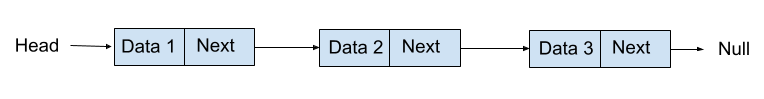

## 1. Definition
A **Singly Linked List** is a linear data structure where elements are not stored at contiguous memory locations. Instead, each element (node) points to the next element in the sequence using a pointer.

## 2. Node Structure
Each node in a singly linked list consists of two parts:
- **Data**: The value stored in the node.
- **Next**: A pointer/reference to the next node in the list.

## 3. Linked Lists vs. Arrays
| Feature | Array | Linked List |
| :--- | :--- | :--- |
| **Size** | Fixed size | Dynamic size |
| **Memory Allocation** | Contiguous | Non-contiguous |
| **Insertion/Deletion** | Costly (shifting required) | Efficient (pointer update) |
| **Access Time** | O(1) - Random Access | O(n) - Sequential Access |

## 4. Advantages & Disadvantages
### Advantages
- Dynamic size: Can grow or shrink at runtime.
- Efficient insertion and deletion at the beginning.
### Disadvantages
- Extra memory required for pointers.
- No random access; must traverse from the head.
- Not cache-friendly due to non-contiguous memory.

## 5. Basic Operations
- **Traversal**: Visiting each node starting from the head.
- **Insertion**: Adding a node at the head, tail, or specific position.
- **Deletion**: Removing a node and re-linking the previous node to the next.
- **Search**: Finding a node with a specific value.

## 6. C++ Implementation

Below is a complete C++ implementation of a Singly Linked List. It includes the `Node` structure, the `LinkedList` class with methods for basic operations (insertion, searching, deletion, and traversal), and a `main` function to demonstrate its usage.

In [21]:
%%writefile solutions.cpp
#include <iostream>

// Node Structure
struct Node {
    int data;
    Node* next;

    // Constructor to initialize a node
    Node(int val) {
        data = val;
        next = nullptr;
    }
};

// LinkedList Class
class LinkedList {
private:
    Node* head;

public:
    LinkedList() : head(nullptr) {}

    // Destructor to free memory
    ~LinkedList() {
        Node* current = head;
        while (current != nullptr) {
            Node* next = current->next;
            delete current;
            current = next;
        }
    }

    // Insert at the beginning
    void insertAtHead(int val) {
        Node* newNode = new Node(val);
        newNode->next = head;
        head = newNode;
    }

    // Insert at the end
    void insertAtTail(int val) {
        Node* newNode = new Node(val);
        if (head == nullptr) {
            head = newNode;
            return;
        }
        Node* temp = head;
        while (temp->next != nullptr) {
            temp = temp->next;
        }
        temp->next = newNode;
    }

    // Search for a value
    bool search(int val) {
        Node* temp = head;
        while (temp != nullptr) {
            if (temp->data == val) {
                return true;
            }
            temp = temp->next;
        }
        return false;
    }

    // Delete a node by value (first occurrence)
    void deleteNode(int val) {
        if (head == nullptr) return;

        // If the head needs to be removed
        if (head->data == val) {
            Node* temp = head;
            head = head->next;
            delete temp;
            return;
        }

        Node* current = head;
        while (current->next != nullptr && current->next->data != val) {
            current = current->next;
        }

        // If the value was found
        if (current->next != nullptr) {
            Node* temp = current->next;
            current->next = current->next->next;
            delete temp;
        }
    }

    // Traverse and print the list
    void display() {
        Node* temp = head;
        while (temp != nullptr) {
            std::cout << temp->data << " -> ";
            temp = temp->next;
        }
        std::cout << "NULL" << std::endl;
    }
};

// Main function to demonstrate usage
int main() {
    LinkedList list;

    std::cout << "Inserting 10 and 20 at head, then 30 at tail:" << std::endl;
    list.insertAtHead(20);
    list.insertAtHead(10);
    list.insertAtTail(30);

    std::cout << "Current List: ";
    list.display();

    std::cout << "\nSearching for 20: " << (list.search(20) ? "Found" : "Not Found") << std::endl;
    std::cout << "Searching for 40: " << (list.search(40) ? "Found" : "Not Found") << std::endl;

    std::cout << "\nDeleting 20..." << std::endl;
    list.deleteNode(20);

    std::cout << "Current List: ";
    list.display();

    return 0;
}


Overwriting solutions.cpp


In [22]:
!g++ solutions.cpp -o solutions
!./solutions

Inserting 10 and 20 at head, then 30 at tail:
Current List: 10 -> 20 -> 30 -> NULL

Searching for 20: Found
Searching for 40: Not Found

Deleting 20...
Current List: 10 -> 30 -> NULL


## 7. Doubly Linked Lists

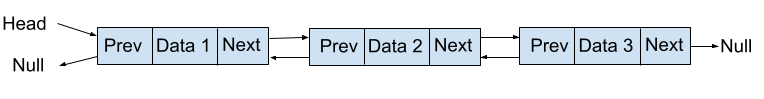



A **Doubly Linked List** is a variation of the singly linked list where each node contains an extra pointer. This extra pointer (typically called `prev`) points to the previous node in the sequence, allowing traversal in both forward and backward directions.

### Node Structure
Each node in a doubly linked list consists of three parts:
- **Data**: The value stored in the node.
- **Next**: A pointer to the next node.
- **Prev**: A pointer to the previous node.

### Advantages over Singly Linked Lists
- **Two-way Traversal**: You can iterate through the list from head to tail, or tail to head.
- **Easier Deletion**: If you have a pointer to the node to be deleted, you don't need to traverse the list to find its predecessor.

### Disadvantages
- **More Memory**: Each node requires extra space for the `prev` pointer.
- **Complex Operations**: Insertions and deletions require modifying more pointers compared to a singly linked list.

### C++ Implementation of Doubly Linked List
Below is a C++ implementation showcasing a doubly linked list with insertions and two-way traversal.

In [23]:
%%writefile doubly_linked_list.cpp
#include <iostream>

// Doubly Linked List Node Structure
struct DNode {
    int data;
    DNode* next;
    DNode* prev;

    DNode(int val) {
        data = val;
        next = nullptr;
        prev = nullptr;
    }
};

class DoublyLinkedList {
private:
    DNode* head;

public:
    DoublyLinkedList() : head(nullptr) {}

    // Insert at the beginning
    void insertAtHead(int val) {
        DNode* newNode = new DNode(val);
        if (head != nullptr) {
            head->prev = newNode;
            newNode->next = head;
        }
        head = newNode;
    }

    // Insert at the end
    void insertAtTail(int val) {
        DNode* newNode = new DNode(val);
        if (head == nullptr) {
            head = newNode;
            return;
        }
        DNode* temp = head;
        while (temp->next != nullptr) {
            temp = temp->next;
        }
        temp->next = newNode;
        newNode->prev = temp;
    }

    // Forward Traversal
    void displayForward() {
        DNode* temp = head;
        std::cout << "Forward: ";
        while (temp != nullptr) {
            std::cout << temp->data << " <-> ";
            temp = temp->next;
        }
        std::cout << "NULL" << std::endl;
    }

    // Backward Traversal
    void displayBackward() {
        if (head == nullptr) return;
        DNode* temp = head;
        // Go to the last node
        while (temp->next != nullptr) {
            temp = temp->next;
        }
        // Traverse backwards
        std::cout << "Backward: ";
        while (temp != nullptr) {
            std::cout << temp->data << " <-> ";
            temp = temp->prev;
        }
        std::cout << "NULL" << std::endl;
    }
};

int main() {
    DoublyLinkedList dll;

    std::cout << "Inserting 10 and 20 at head, then 30 at tail:" << std::endl;
    dll.insertAtHead(20);
    dll.insertAtHead(10);
    dll.insertAtTail(30);

    dll.displayForward();
    dll.displayBackward();

    return 0;
}


Overwriting doubly_linked_list.cpp


In [24]:
!g++ doubly_linked_list.cpp -o doubly_linked_list
!./doubly_linked_list

Inserting 10 and 20 at head, then 30 at tail:
Forward: 10 <-> 20 <-> 30 <-> NULL
Backward: 30 <-> 20 <-> 10 <-> NULL


## 8. Exercises (Singly Linked Lists)
Test your understanding of Singly Linked Lists by trying to implement the following methods in the `LinkedList` class:

1. **`int countNodes()`**: Traverse the list and return the total number of nodes.
2. **`void reverseList()`**: Reverse the singly linked list in place (without allocating new nodes).
3. **`Node* getMiddle()`**: Find and return the middle node of the linked list (hint: use the fast and slow pointer approach).
4. **`bool hasCycle()`**: Detect if there is a cycle or loop in the linked list.
5. **`void deleteNodeByIndex(int index)`**: Delete the node at a specific index.

**Conceptual Questions:**

6. Explain the main difference in time complexity for accessing the *n*-th element in an Array versus a Singly Linked List.
7. Why is a Singly Linked List not suitable if you need to frequently traverse the data in reverse order?

## 9. Exercises (Doubly Linked Lists)

Test your understanding of Doubly Linked Lists by trying to implement the following methods in the `DoublyLinkedList` class:

8. **`void deleteAtHead()`**: Remove the first node of the list and update the `head` and `prev` pointers appropriately.
9. **`void deleteAtTail()`**: Remove the last node of the list.

## 10. Solutions

### Solution to Exercise 1: `countNodes()`
Add this method to your `LinkedList` class to count the nodes:
```cpp
int countNodes() {
    int count = 0;
    Node* temp = head;
    while (temp != nullptr) {
        count++;
        temp = temp->next;
    }
    return count;
}
```

### Solution to Exercise 2: `reverseList()`
Add this method to reverse the pointers of the list in place:
```cpp
void reverseList() {
    Node* prev = nullptr;
    Node* current = head;
    Node* nextNode = nullptr;
    
    while (current != nullptr) {
        nextNode = current->next; // Store next node
        current->next = prev;     // Reverse current node's pointer
        prev = current;           // Move pointers one position ahead
        current = nextNode;
    }
    head = prev; // Update head to the last node
}
```

### Solution to Exercise 3: `getMiddle()`
Add this method to find the middle node using the tortoise and hare approach:
```cpp
Node* getMiddle() {
    if (head == nullptr) return nullptr;
    Node* slow = head;
    Node* fast = head;
    while (fast != nullptr && fast->next != nullptr) {
        slow = slow->next;
        fast = fast->next->next;
    }
    return slow; // slow will point to the middle element
}
```

### Solution to Exercise 4: `hasCycle()`
Add this method to detect a cycle using Floyd's Cycle-Finding Algorithm:
```cpp
bool hasCycle() {
    if (head == nullptr) return false;
    Node* slow = head;
    Node* fast = head;
    while (fast != nullptr && fast->next != nullptr) {
        slow = slow->next;
        fast = fast->next->next;
        if (slow == fast) {
            return true; // Cycle detected
        }
    }
    return false; // No cycle
}
```

### Solution to Exercise 5: `deleteNodeByIndex(int index)`
Add this method to delete a node at a specific index:
```cpp
void deleteNodeByIndex(int index) {
    if (head == nullptr) return; // List is empty

    // If the head needs to be removed
    if (index == 0) {
        Node* temp = head;
        head = head->next;
        delete temp;
        return;
    }

    Node* current = head;
    int count = 0;
    while (current != nullptr && count < index - 1) {
        current = current->next;
        count++;
    }

    // If index is out of bounds or current is null (list is too short)
    if (current == nullptr || current->next == nullptr) {
        return;
    }

    Node* nodeToDelete = current->next;
    current->next = nodeToDelete->next;
    delete nodeToDelete;
}
```

### Solution to Conceptual Question 6
In an **Array**, accessing the *n*-th element takes **O(1)** (constant) time because elements are stored in contiguous memory locations, allowing for direct mathematical calculation of the target address. In a **Singly Linked List**, accessing the *n*-th element takes **O(n)** (linear) time. Since nodes are scattered in memory, you must sequentially traverse the list from the head node using the `next` pointers to find the specific element.

### Solution to Conceptual Question 7
A Singly Linked List only maintains `next` pointers, meaning traversal can inherently only happen in one direction (forward). To traverse in reverse, you would either need to repeatedly traverse from the head to find the predecessor of each node (which takes **O(n²)** time) or use auxiliary memory like a Stack to store the nodes temporarily (which takes **O(n)** space). If you frequently need to traverse backwards, a Doubly Linked List is a much more suitable and efficient choice.

### Solution to Exercise 8: `deleteAtHead()`
Add this method to your `DoublyLinkedList` class to delete the first node:
```cpp
void deleteAtHead() {
    if (head == nullptr) return; // List is empty
    
    DNode* temp = head;
    head = head->next;
    
    if (head != nullptr) {
        head->prev = nullptr;
    }
    delete temp;
}
```

### Solution to Exercise 9: `deleteAtTail()`
Add this method to remove the last node of the list:
```cpp
void deleteAtTail() {
    if (head == nullptr) return; // List is empty
    
    // If there is only one node
    if (head->next == nullptr) {
        delete head;
        head = nullptr;
        return;
    }
    
    DNode* temp = head;
    while (temp->next != nullptr) {
        temp = temp->next;
    }
    
    temp->prev->next = nullptr;
    delete temp;
}
```

In [20]:
import graphviz
from IPython.display import display, clear_output
import ipywidgets as widgets

def draw_state(nodes_dict, edges_list, pointers_dict, msg):
    dot = graphviz.Digraph(engine='dot')
    dot.attr(rankdir='LR', size='10,4')
    dot.attr(label=msg, labelloc='t', fontsize='16', fontname='Helvetica')
    dot.attr('node', shape='record', style='filled', fillcolor='aliceblue', fontname='Helvetica')

    # Add nodes
    for n_id, val in nodes_dict.items():
        if val == 'NULL':
            dot.node(n_id, 'NULL', shape='none', fillcolor='white')
        else:
            # Color the newly inserted node differently
            fill = 'lemonchiffon' if n_id == 'n30' else 'aliceblue'
            # Using {{ }} in f-string to output {} in graphviz, forcing horizontal layout
            dot.node(n_id, f"{{ <f0> {val} | <f1> }}", fillcolor=fill)

    # Add edges
    for src, dst in edges_list:
        if src in nodes_dict and dst in nodes_dict:
            target = dst if nodes_dict[dst] == 'NULL' else f"{dst}:f0"
            dot.edge(f"{src}:f1", target)

    # Add pointers (head, temp, newNode, current)
    for ptr_name, target_id in pointers_dict.items():
        color_map = {'head': 'blue', 'newNode': 'green', 'temp': 'orange', 'current': 'purple'}
        color = color_map.get(ptr_name, 'red')
        dot.node(ptr_name, ptr_name, shape='none', fillcolor='white', fontcolor=color)
        if target_id in nodes_dict:
            target = target_id if nodes_dict[target_id] == 'NULL' else f"{target_id}:f0"
            dot.edge(ptr_name, target, color=color, style='dashed')

    return dot

# Define precise states matching the code execution steps for insertAtHead and deleteNode
states = [
    {
        "msg": "1. Initial List (10 -> 20 -> 40)",
        "nodes": {"n10": "10", "n20": "20", "n40": "40", "null": "NULL"},
        "edges": [("n10", "n20"), ("n20", "n40"), ("n40", "null")],
        "pointers": {"head": "n10"}
    },
    {
        "msg": "2. list.insertAtHead(30): Node* newNode = new Node(30);",
        "nodes": {"n10": "10", "n20": "20", "n40": "40", "n30": "30", "null": "NULL", "null2": "NULL"},
        "edges": [("n10", "n20"), ("n20", "n40"), ("n40", "null"), ("n30", "null2")],
        "pointers": {"head": "n10", "newNode": "n30"}
    },
    {
        "msg": "3. newNode->next = head;",
        "nodes": {"n10": "10", "n20": "20", "n40": "40", "n30": "30", "null": "NULL"},
        "edges": [("n30", "n10"), ("n10", "n20"), ("n20", "n40"), ("n40", "null")],
        "pointers": {"head": "n10", "newNode": "n30"}
    },
    {
        "msg": "4. head = newNode;",
        "nodes": {"n10": "10", "n20": "20", "n40": "40", "n30": "30", "null": "NULL"},
        "edges": [("n30", "n10"), ("n10", "n20"), ("n20", "n40"), ("n40", "null")],
        "pointers": {"head": "n30", "newNode": "n30"}
    },
    {
        "msg": "5. Insertion complete. Next: list.deleteNode(20)",
        "nodes": {"n10": "10", "n20": "20", "n40": "40", "n30": "30", "null": "NULL"},
        "edges": [("n30", "n10"), ("n10", "n20"), ("n20", "n40"), ("n40", "null")],
        "pointers": {"head": "n30"}
    },
    {
        "msg": "6. list.deleteNode(20): Node* current = head;",
        "nodes": {"n10": "10", "n20": "20", "n40": "40", "n30": "30", "null": "NULL"},
        "edges": [("n30", "n10"), ("n10", "n20"), ("n20", "n40"), ("n40", "null")],
        "pointers": {"head": "n30", "current": "n30"}
    },
    {
        "msg": "7. while (... current->next->data != 20) { current = current->next; } // current moves to 10",
        "nodes": {"n10": "10", "n20": "20", "n40": "40", "n30": "30", "null": "NULL"},
        "edges": [("n30", "n10"), ("n10", "n20"), ("n20", "n40"), ("n40", "null")],
        "pointers": {"head": "n30", "current": "n10"}
    },
    {
        "msg": "8. Node* temp = current->next; // (temp points to the 3rd node to be deleted)",
        "nodes": {"n10": "10", "n20": "20", "n40": "40", "n30": "30", "null": "NULL"},
        "edges": [("n30", "n10"), ("n10", "n20"), ("n20", "n40"), ("n40", "null")],
        "pointers": {"head": "n30", "current": "n10", "temp": "n20"}
    },
    {
        "msg": "9. current->next = current->next->next;",
        "nodes": {"n10": "10", "n20": "20", "n40": "40", "n30": "30", "null": "NULL"},
        "edges": [("n30", "n10"), ("n10", "n40"), ("n20", "n40"), ("n40", "null")],
        "pointers": {"head": "n30", "current": "n10", "temp": "n20"}
    },
    {
        "msg": "10. delete temp; // Memory freed",
        "nodes": {"n10": "10", "n40": "40", "n30": "30", "null": "NULL"},
        "edges": [("n30", "n10"), ("n10", "n40"), ("n40", "null")],
        "pointers": {"head": "n30", "current": "n10"}
    },
    {
        "msg": "11. Deletion complete. Final List.",
        "nodes": {"n10": "10", "n40": "40", "n30": "30", "null": "NULL"},
        "edges": [("n30", "n10"), ("n10", "n40"), ("n40", "null")],
        "pointers": {"head": "n30"}
    }
]

# Interactive UI Setup
current_step = 0
out = widgets.Output()

def render_step(step_idx):
    with out:
        clear_output(wait=True)
        state = states[step_idx]
        dot = draw_state(state["nodes"], state["edges"], state["pointers"], state["msg"])
        display(dot)

btn_prev = widgets.Button(description='◀ Prev', button_style='info')
btn_next = widgets.Button(description='Next ▶', button_style='info')

def update_buttons():
    btn_prev.disabled = (current_step == 0)
    btn_next.disabled = (current_step == len(states) - 1)

def on_prev_clicked(b):
    global current_step
    if current_step > 0:
        current_step -= 1
        render_step(current_step)
        update_buttons()

def on_next_clicked(b):
    global current_step
    if current_step < len(states) - 1:
        current_step += 1
        render_step(current_step)
        update_buttons()

btn_prev.on_click(on_prev_clicked)
btn_next.on_click(on_next_clicked)

# Initial render
render_step(current_step)
update_buttons()

# Display controls and output
controls = widgets.HBox([btn_prev, btn_next])
display(controls, out)

Output()